In [1]:
import os
import sys
root = os.path.abspath("..")
sys.path.append(root)

import io
import shutil
import pickle
import torch
import re
import json
import numpy as np
import matplotlib.pyplot as plt
import scienceplots
from datetime import datetime
from collections import defaultdict

from config import Config
from simulation.impl.trajectory_with_metrics import TrajectoryWithMetrics

if shutil.which("latex"):
    plt.style.use(["science", "ieee"])
else:
    plt.style.use(["science", "ieee", "no-latex"])

config = Config()
figures_dir = os.path.join(config.resource_dir, "figures")
os.makedirs(figures_dir, exist_ok=True)

/Users/alla1854/Documents/Documents - Alfred’s MacBook Pro/Projects/PhD/AutoscalingArchitecture/Code/.env/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
class CPU_Unpickler(pickle.Unpickler):
    def find_class(self, module, name):
        if module == 'torch.storage' and name == '_load_from_bytes':
            return lambda b: torch.load(io.BytesIO(b), map_location='cpu')
        return super().find_class(module, name)

In [ ]:
TRAJECTORY_DIR = "path/to/trajectories"
EXPERIMENT_DIR = os.path.abspath("../experiments")
CLIENT_CPU_BASE = 200.0  # 1x client CPU baseline


def get_policy_label(experiment):
    policy = experiment["server_policy"]
    scale = experiment.get("server_policy_smart_priority_scale", 1.0)
    if policy == "smart" and float(scale) > 1.0:
        return "smartx"
    return policy


def load_records():
    datetimes = {}
    paths = {}
    devices = {}

    for filename in os.listdir(TRAJECTORY_DIR):
        if not filename.startswith("trajectory_exp_simulation"):
            continue
        match = re.findall(r"trajectory_exp_simulation_(.+)_(.+)_(.+)\.pkl", filename)
        if not match:
            continue
        device, idx, date_str = match[0]
        idx = int(idx)
        date_str = datetime.fromisoformat(date_str)
        if idx not in datetimes or date_str > datetimes[idx]:
            devices[idx] = device
            paths[idx] = os.path.join(TRAJECTORY_DIR, filename)
            datetimes[idx] = date_str

    records = []
    for idx, path in paths.items():
        exp_path = os.path.join(EXPERIMENT_DIR, f"exp_simulation_{devices[idx]}_{idx}.json")
        if not os.path.exists(exp_path):
            continue
        with open(exp_path) as f:
            experiment = json.load(f)
        records.append((idx, path, experiment))

    print(f"Loaded {len(records)} records")
    return records


records = load_records()

Loaded 160 records


In [4]:
# key: (policy, server_mult, n_clients, client_mult) -> list of (total_finished, total_cancelled)
data = defaultdict(list)

for idx, path, exp in records:
    trajectory: TrajectoryWithMetrics = CPU_Unpickler(open(path, "rb")).load()

    total_finished = sum(sum(ts) for ts in trajectory.finished_queries)
    total_cancelled = sum(sum(ts) for ts in trajectory.cancelled_queries)

    policy = get_policy_label(exp)
    server_cpu = exp["available_resource_params"]["server"]["cpu"]["max"]
    client_cpu = exp["available_resource_params"]["client"]["cpu"]["max"]
    n_clients = exp["n_clients"]

    server_mult = int(round(server_cpu / CLIENT_CPU_BASE))
    client_mult = int(round(client_cpu / CLIENT_CPU_BASE))

    data[(policy, server_mult, n_clients, client_mult)].append((total_finished, total_cancelled))

print(f"Unique (policy, server_mult, n_clients, client_mult) keys: {len(data)}")

Unique (policy, server_mult, n_clients, client_mult) keys: 160


In [ ]:
POLICIES = ["centralized", "default", "smart"]#, "smartx"]
POLICY_LABELS = ["Centralized", "Uniform", "Affinity"]#, "SmartX"]

server_mults = sorted({k[1] for k in data})
x_configs = sorted({(k[2], k[3]) for k in data})  # (n_clients, client_mult)

def fmt_clients(n):
    if n >= 1000:
        return f"{n // 1000}k"
    return str(n)

x_labels = [f"{fmt_clients(n)}\n{m}x" for n, m in x_configs]
x_pos = list(range(len(x_configs)))

print("Server multipliers:", server_mults)
print("Client configurations:", x_configs)

Server multipliers: [10, 30, 50, 80, 100]
Client configurations: [(100, 1), (100, 2), (1000, 1), (1000, 2), (5000, 1), (5000, 2), (10000, 1), (10000, 2)]


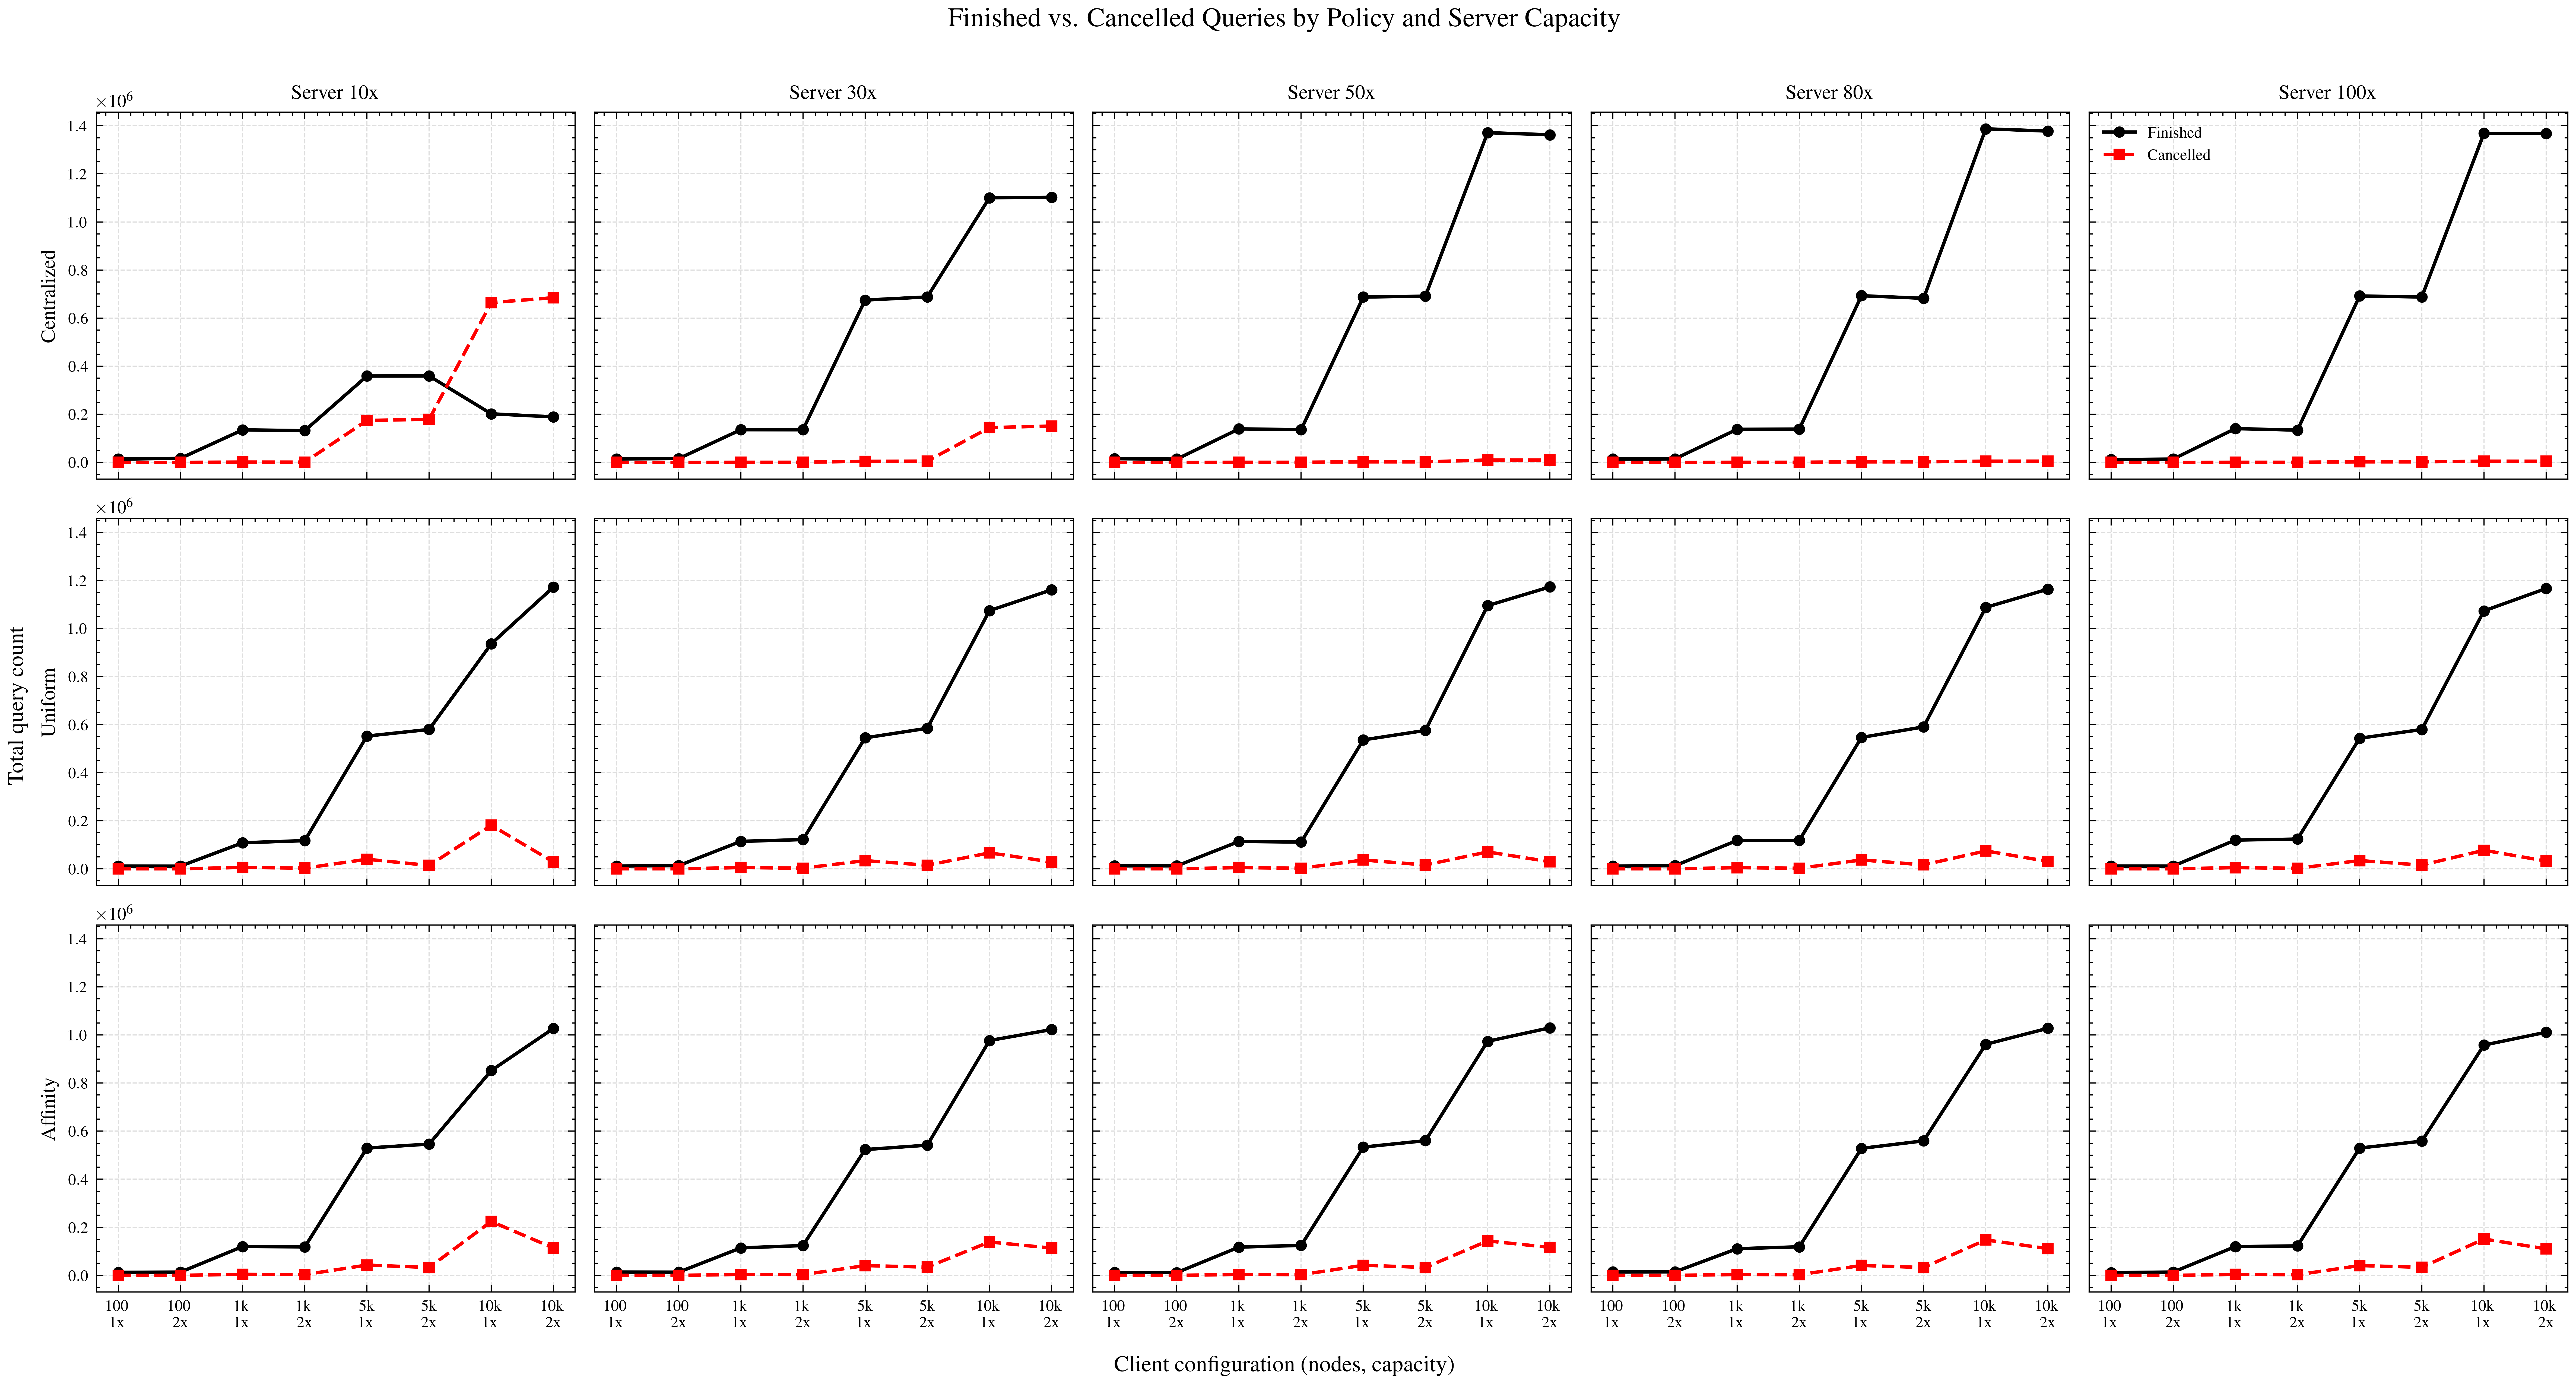

In [6]:
n_rows = len(POLICIES)
n_cols = len(server_mults)

_theme_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
COLOR_FINISHED  = _theme_colors[0]
COLOR_CANCELLED = _theme_colors[1]

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(3.2 * n_cols, 2.8 * n_rows),
    sharex=True,
    sharey=True
)

for row, (policy, policy_label) in enumerate(zip(POLICIES, POLICY_LABELS)):
    for col, server_mult in enumerate(server_mults):
        ax = axes[row, col]

        finished_vals = []
        cancelled_vals = []

        for n_clients, client_mult in x_configs:
            key = (policy, server_mult, n_clients, client_mult)
            if key in data:
                entries = data[key]
                finished_vals.append(np.mean([e[0] for e in entries]))
                cancelled_vals.append(np.mean([e[1] for e in entries]))
            else:
                finished_vals.append(np.nan)
                cancelled_vals.append(np.nan)

        ax.plot(x_pos, finished_vals, color=COLOR_FINISHED, marker="o", markersize=4,
                linewidth=1.5, label="Finished")
        ax.plot(x_pos, cancelled_vals, color=COLOR_CANCELLED, marker="s", markersize=4,
                linewidth=1.5, label="Cancelled")

        ax.set_xticks(x_pos)
        ax.set_xticklabels(x_labels, fontsize=7)
        ax.tick_params(axis="y", labelsize=7)
        ax.tick_params(axis="x", which="minor", bottom=False)
        ax.grid(True, linestyle="--", alpha=0.4)

        if row == 0:
            ax.set_title(f"Server {server_mult}x", fontsize=9, fontweight="bold")
        if col == 0:
            ax.set_ylabel(policy_label, fontsize=9, fontweight="bold")
        if row == 0 and col == n_cols - 1:
            ax.legend(fontsize=7, loc="upper left")

fig.supxlabel("Client configuration (nodes, capacity)", fontsize=10, y=0.01)
fig.supylabel("Total query count", fontsize=10, x=0.01)
fig.suptitle("Finished vs. Cancelled Queries by Policy and Server Capacity", fontsize=12, y=1.01)

plt.tight_layout()
plt.savefig(os.path.join(figures_dir, "query_completion_grid.pdf"), bbox_inches="tight")
plt.show()

Figure 1 — server 10x  →  query_completion_server_10x.pdf


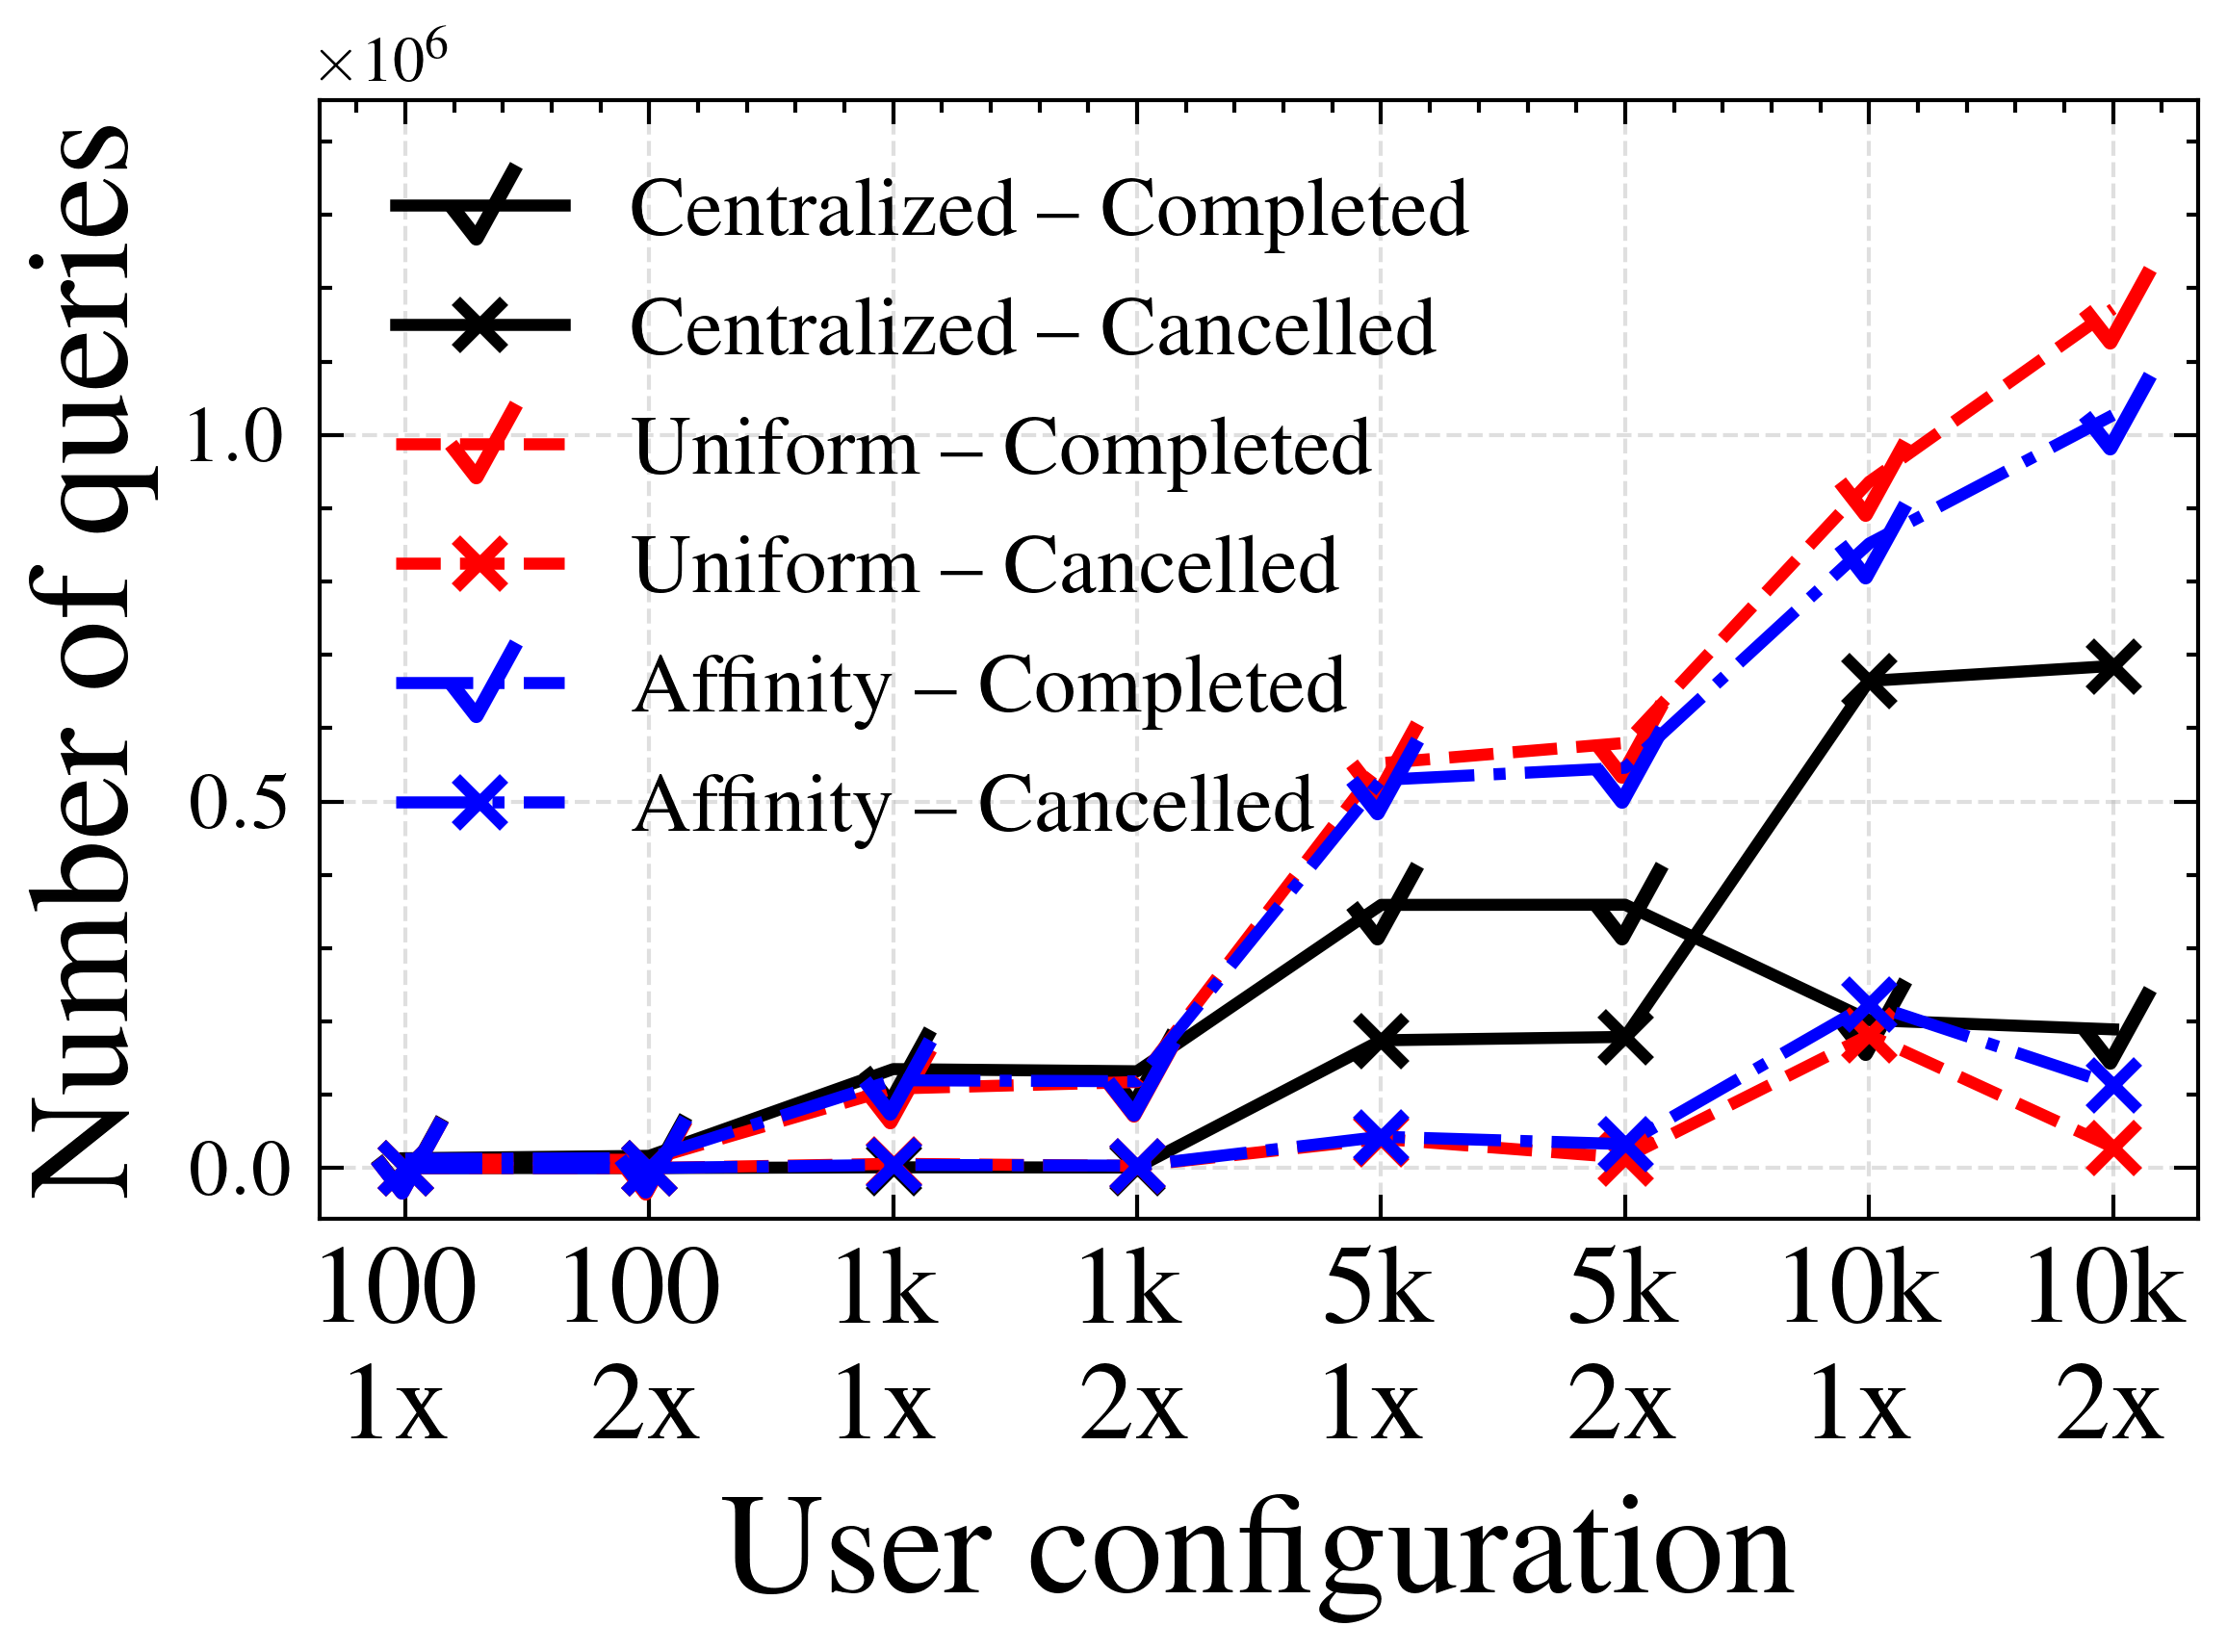

Figure 2 — server 30x  →  query_completion_server_30x.pdf


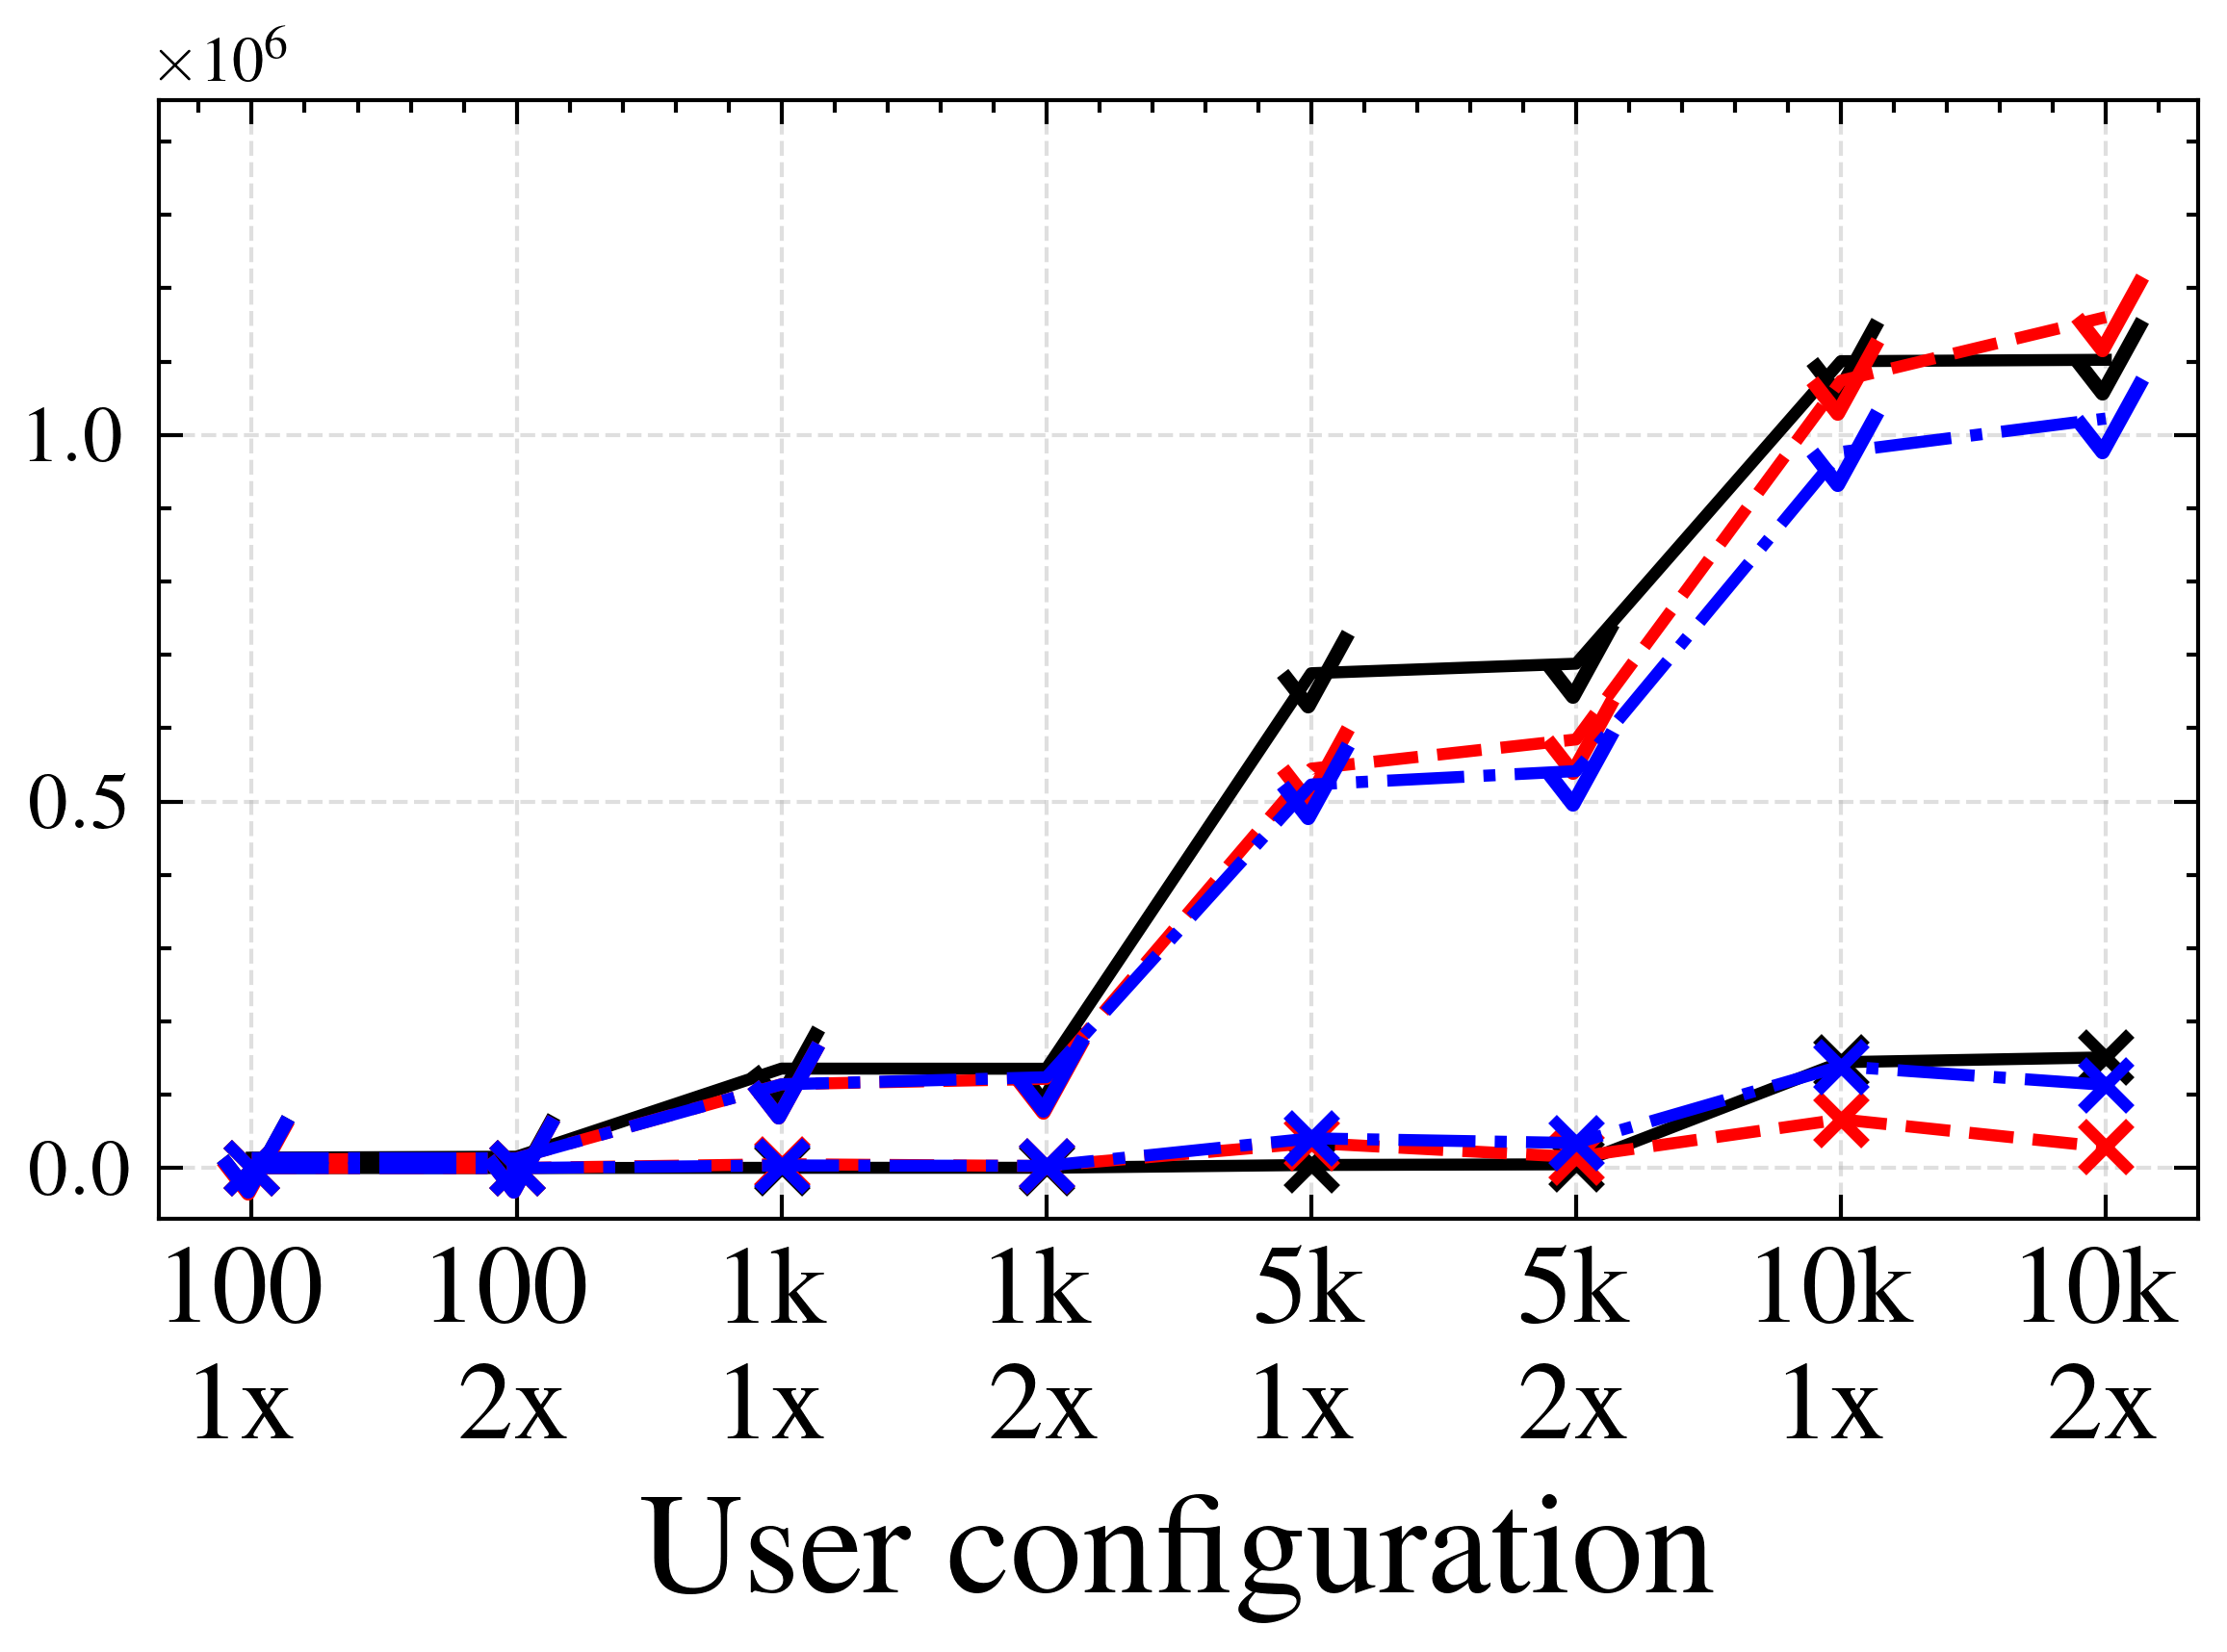

Figure 3 — server 50x  →  query_completion_server_50x.pdf


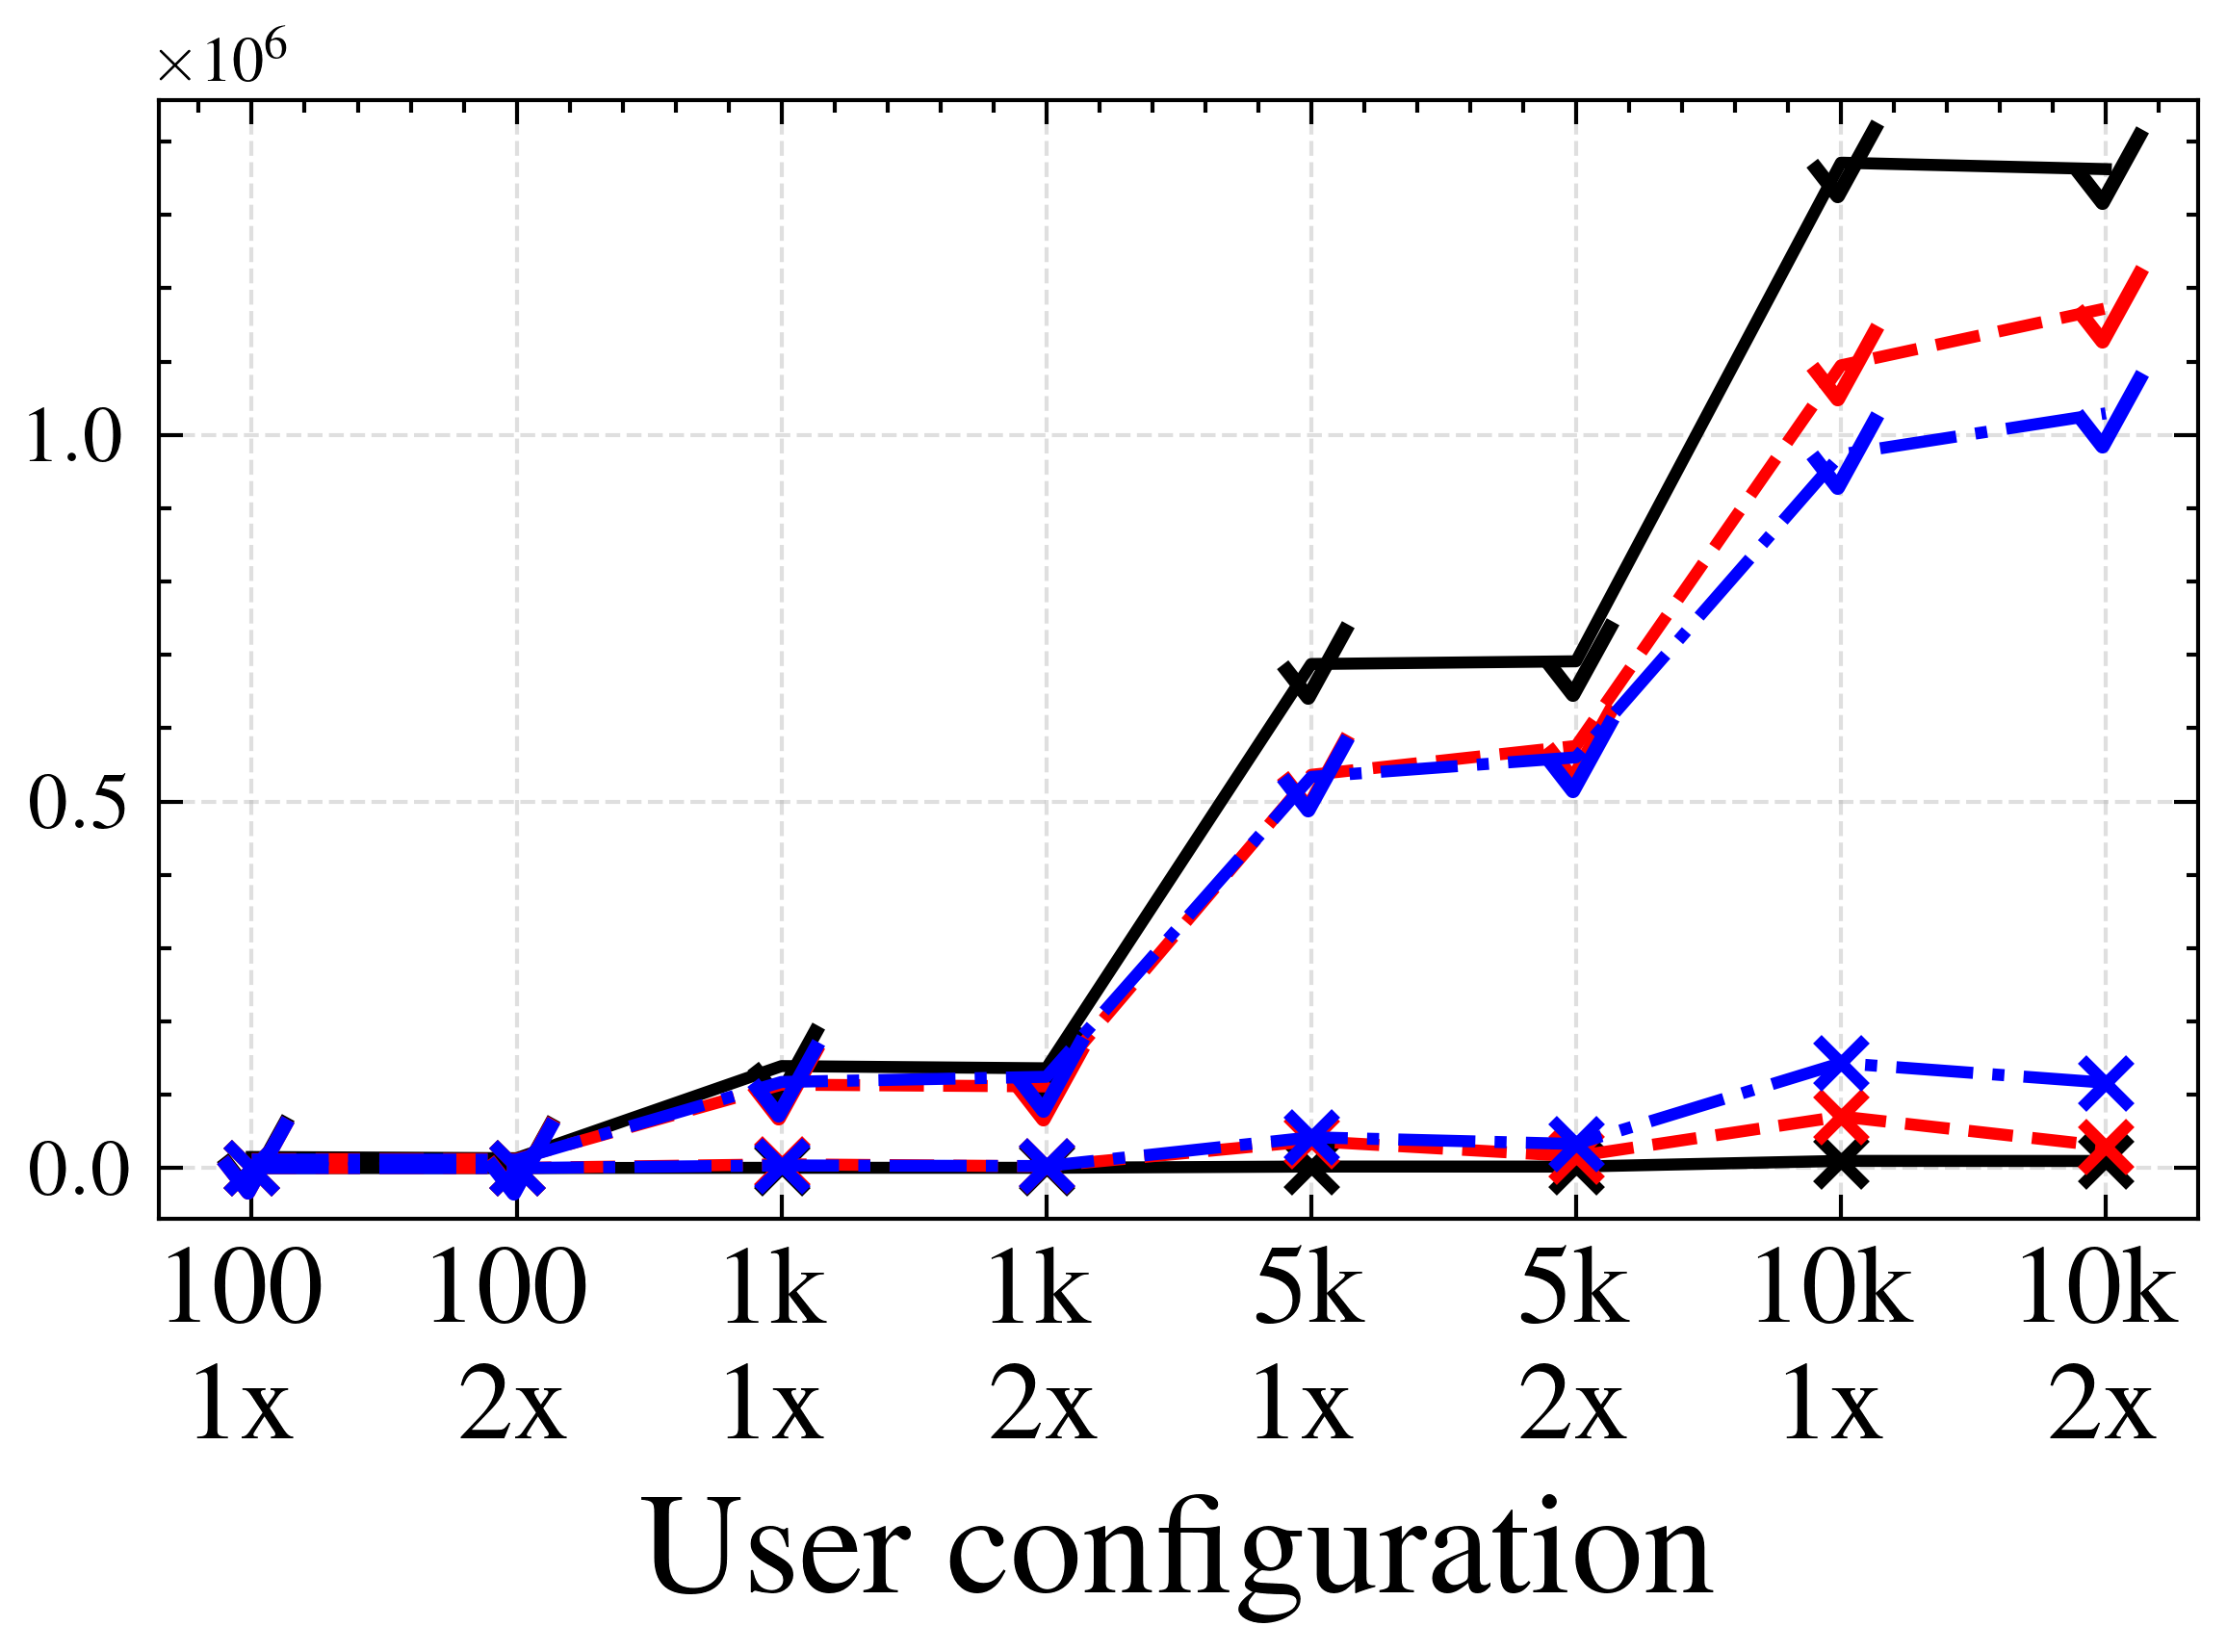

Figure 4 — server 80x  →  query_completion_server_80x.pdf


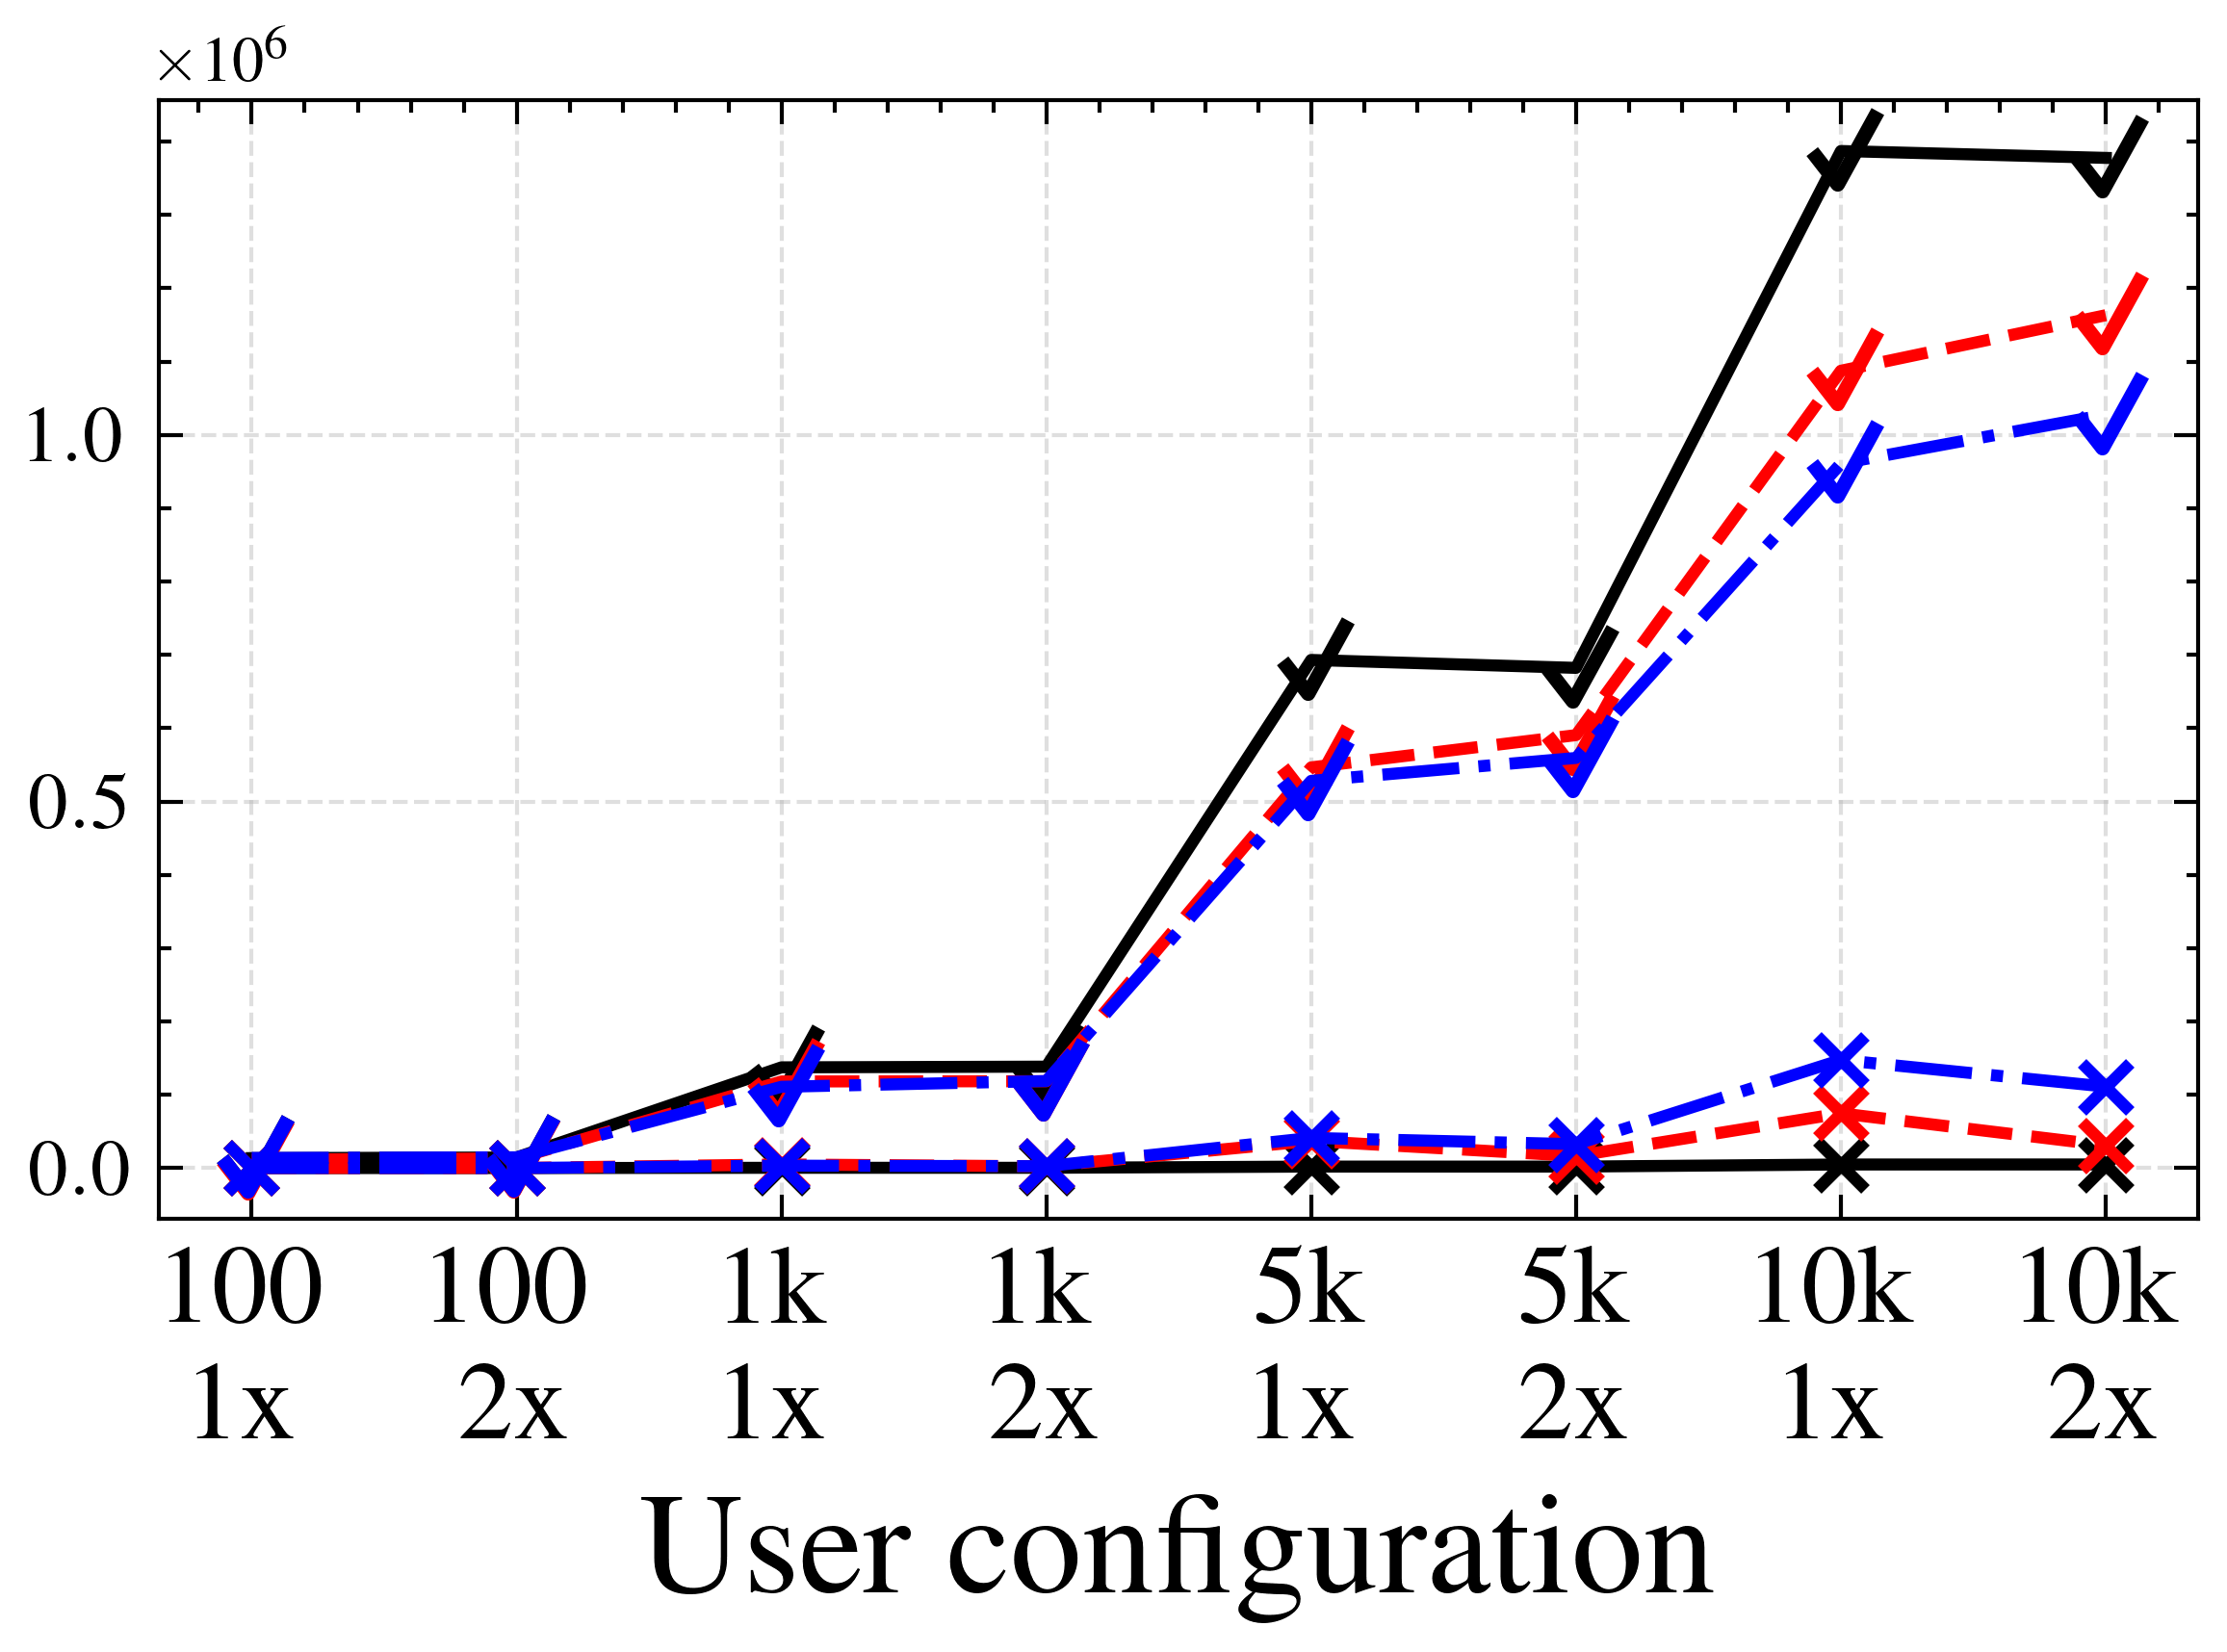

Figure 5 — server 100x  →  query_completion_server_100x.pdf


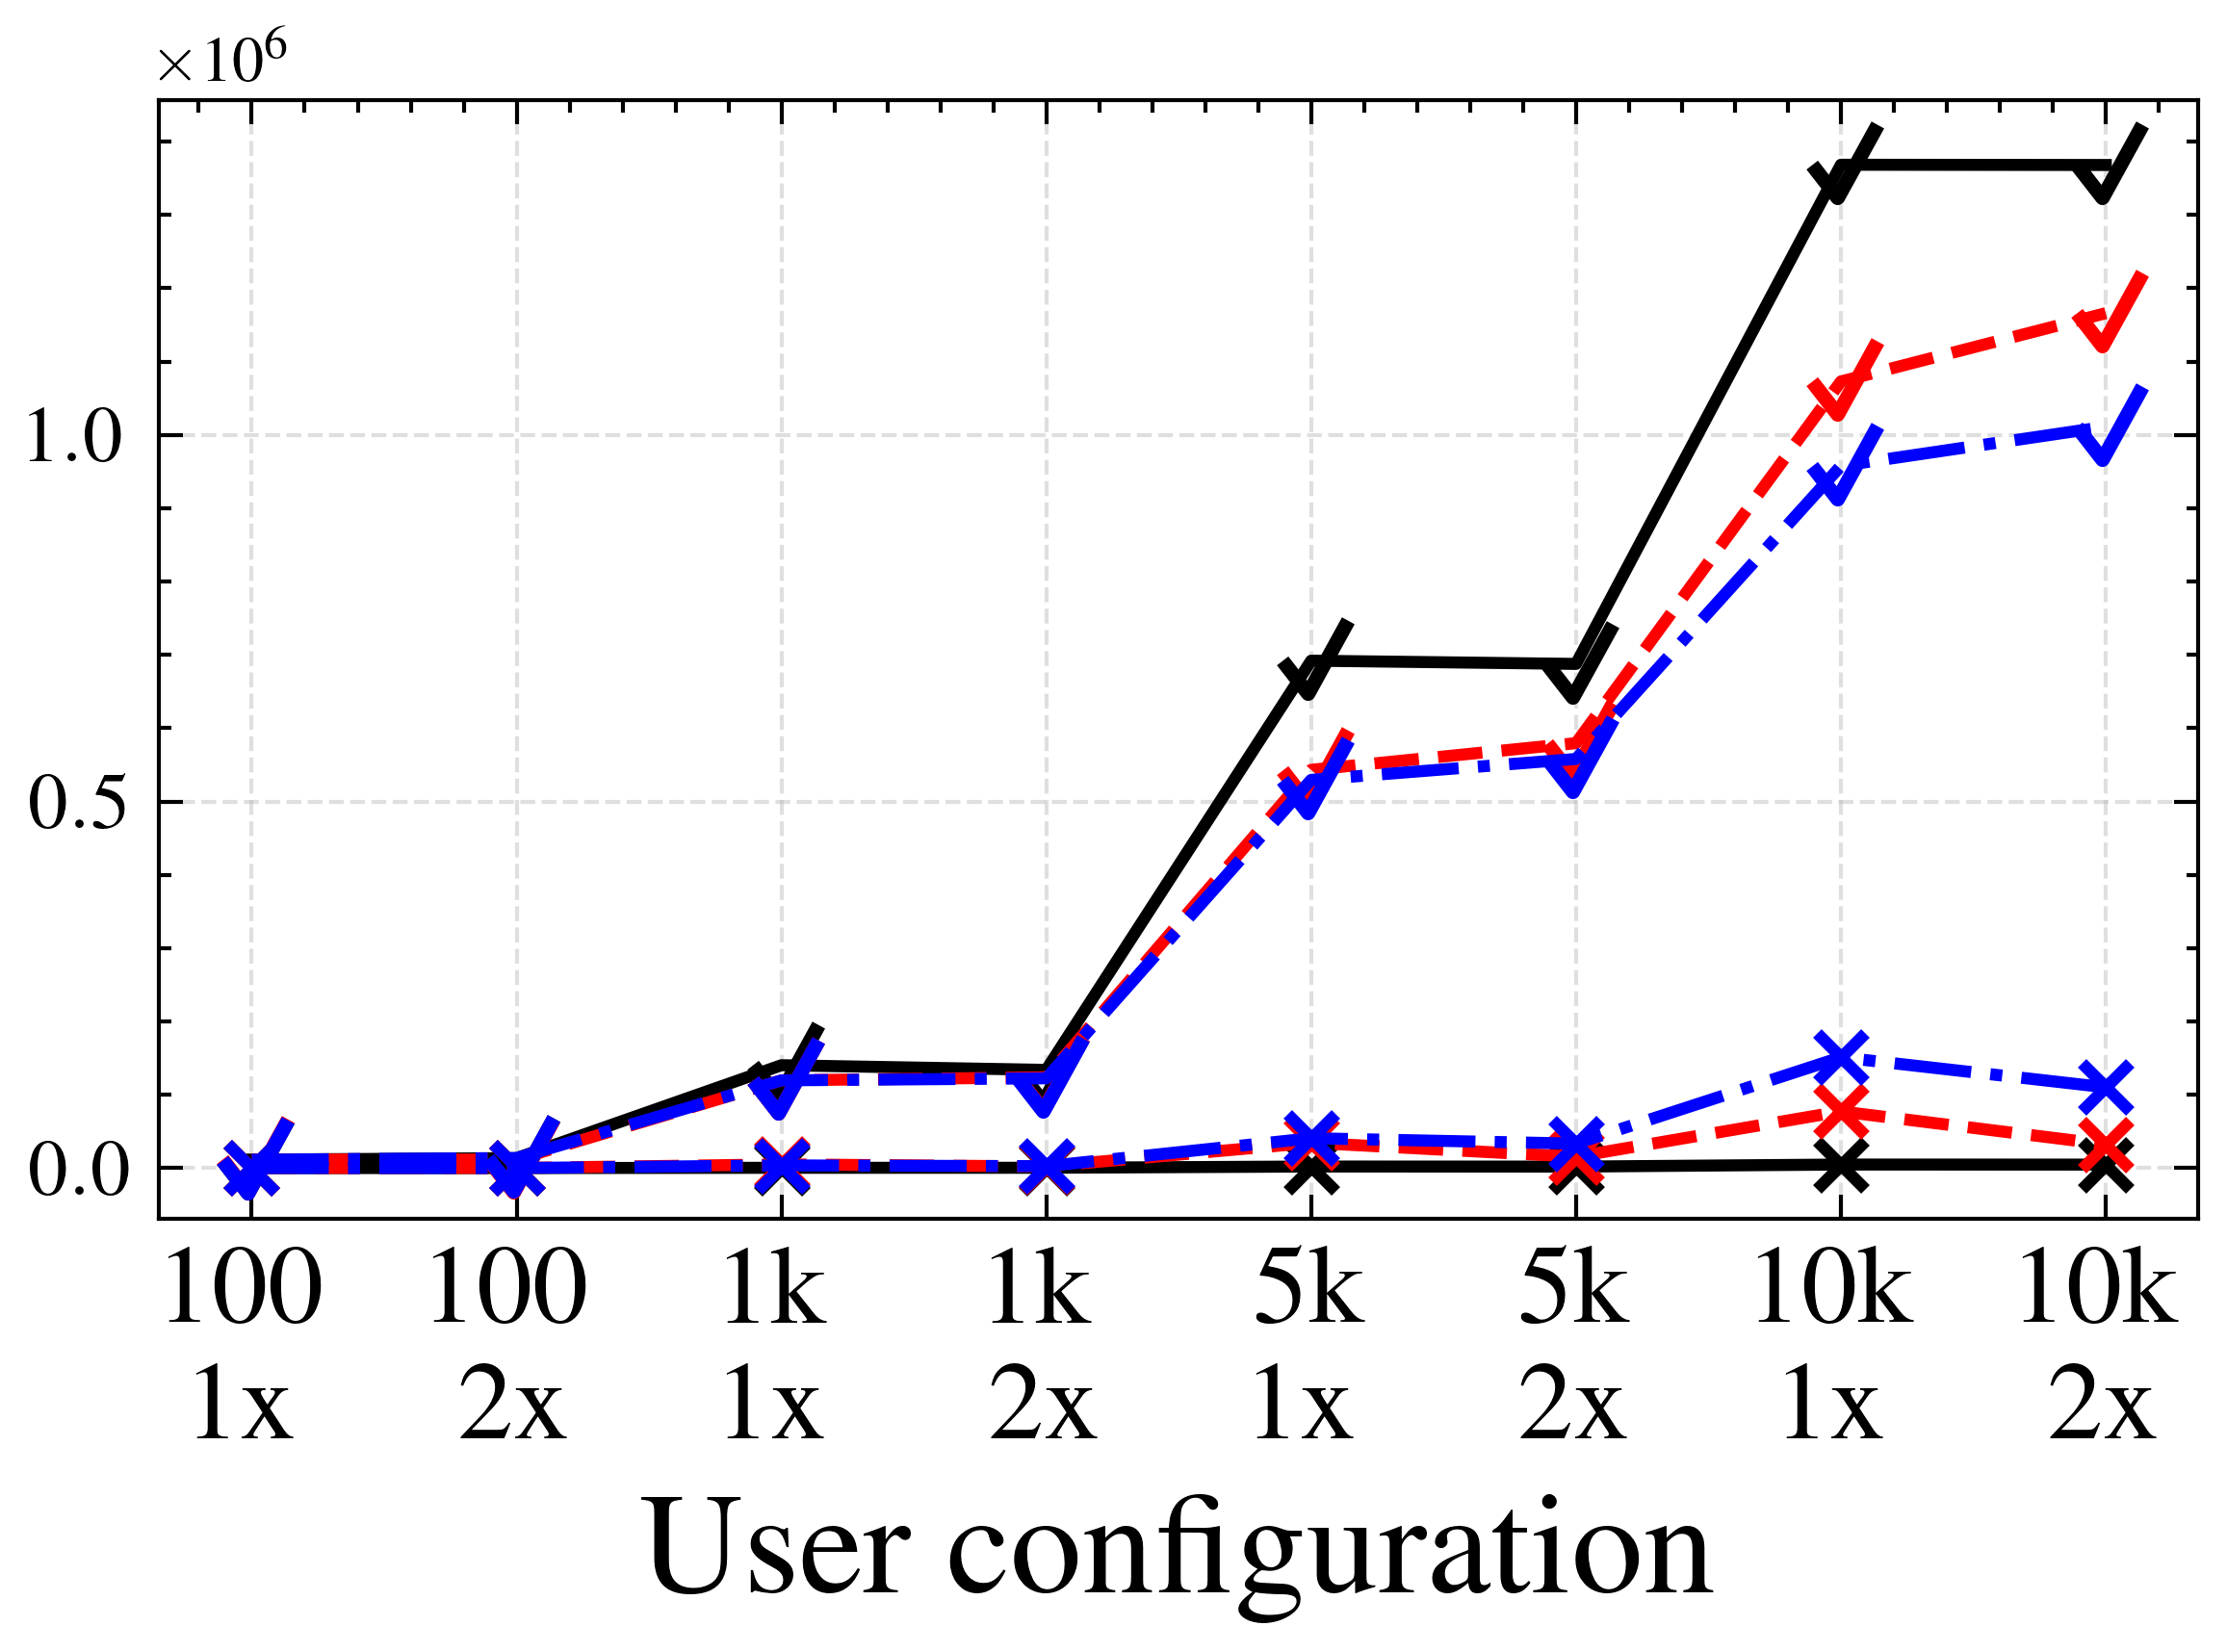

In [7]:
import matplotlib.path as mpath

# Custom checkmark marker path (✓)
_check_verts = [(-0.4, 0.0), (-0.05, -0.45), (0.5, 0.55)]
_check_codes = [mpath.Path.MOVETO, mpath.Path.LINETO, mpath.Path.LINETO]
MARKER_FINISHED  = mpath.Path(_check_verts, _check_codes)
MARKER_CANCELLED = "x"

_theme_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]
POLICY_COLORS = {policy: _theme_colors[i] for i, policy in enumerate(POLICIES)}

POLICY_LINESTYLES = {
    "centralized": "-",
    "default":     "--",
    "smart":       "-.",
    "smartx":      ":",
}

# Pre-compute all values to derive a shared y range across all figures
_all_vals = {}
for server_mult in server_mults:
    for policy in POLICIES:
        finished_vals, cancelled_vals = [], []
        for n_clients, client_mult in x_configs:
            key = (policy, server_mult, n_clients, client_mult)
            if key in data:
                entries = data[key]
                finished_vals.append(np.mean([e[0] for e in entries]))
                cancelled_vals.append(np.mean([e[1] for e in entries]))
            else:
                finished_vals.append(np.nan)
                cancelled_vals.append(np.nan)
        _all_vals[(server_mult, policy)] = (finished_vals, cancelled_vals)

_finite = [v for fv, cv in _all_vals.values() for v in fv + cv if not np.isnan(v)]
_y_pad  = (max(_finite) - min(_finite)) * 0.05
_ylim   = (min(_finite) - _y_pad, max(_finite) + _y_pad)

# x positions 0 and 1 correspond to 100-node configs (1x and 2x)
ZOOM_XI = [0, 1]

# One figure per server capacity
for i, server_mult in enumerate(server_mults):
    fig, ax = plt.subplots(figsize=(4, 3))

    for policy, policy_label in zip(POLICIES, POLICY_LABELS):
        color = POLICY_COLORS[policy]
        ls    = POLICY_LINESTYLES[policy]
        finished_vals, cancelled_vals = _all_vals[(server_mult, policy)]

        ax.plot(x_pos, finished_vals, color=color, linestyle=ls,
                marker=MARKER_FINISHED,  markersize=10, markeredgewidth=1.8,
                markerfacecolor="none", markeredgecolor=color,
                linewidth=1.5, label=f"{policy_label} – Completed")
        ax.plot(x_pos, cancelled_vals, color=color, linestyle=ls,
                marker=MARKER_CANCELLED, markersize=6,  markeredgewidth=1.5,
                linewidth=1.5, label=f"{policy_label} – Cancelled")

    ax.set_ylim(_ylim)
    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels, fontsize=14)
    ax.tick_params(axis="y", labelsize=10)
    ax.tick_params(axis="x", which="minor", bottom=False)
    ax.set_xlabel("User configuration", fontsize=18)
    ax.grid(True, linestyle="--", alpha=0.4)

    if i == 0:
        ax.set_ylabel("Number of queries", fontsize=18)
        ax.legend(fontsize=10.5, loc="upper left", ncol=1)

    # Inset: zoom into 100-node region (x positions 0 and 1)
    zoom_y = [
        v
        for policy in POLICIES
        for vals in _all_vals[(server_mult, policy)]
        for xi in ZOOM_XI
        for v in [vals[xi]]
        if not np.isnan(v)
    ]
    # if zoom_y:
    #     y_span    = max(zoom_y) - min(zoom_y)
    #     y_pad     = max(y_span * 0.25, max(zoom_y) * 0.05 + 1.0)
    #     zoom_ylim = (min(zoom_y) - y_pad, max(zoom_y) + y_pad)

    #     # Small inset in the upper-right; connector lines suppressed
    #     axins = ax.inset_axes([0.58, 0.63, 0.38, 0.30])

    #     for policy in POLICIES:
    #         color = POLICY_COLORS[policy]
    #         ls    = POLICY_LINESTYLES[policy]
    #         fv, cv = _all_vals[(server_mult, policy)]

    #         axins.plot(ZOOM_XI, [fv[xi] for xi in ZOOM_XI], color=color, linestyle=ls,
    #                    marker=MARKER_FINISHED, markersize=6, markeredgewidth=1.2,
    #                    markerfacecolor="none", markeredgecolor=color, linewidth=1.0)
    #         axins.plot(ZOOM_XI, [cv[xi] for xi in ZOOM_XI], color=color, linestyle=ls,
    #                    marker=MARKER_CANCELLED, markersize=4, markeredgewidth=1.0,
    #                    linewidth=1.0)

    #     axins.set_xlim(-0.5, 1.5)
    #     axins.set_ylim(zoom_ylim)
    #     axins.set_xticks(ZOOM_XI)
    #     axins.set_xticklabels([x_labels[xi] for xi in ZOOM_XI], fontsize=7)
    #     axins.tick_params(axis="y", labelsize=6)
    #     axins.tick_params(axis="x", which="minor", bottom=False)
    #     axins.grid(True, linestyle="--", alpha=0.3)

    #     # Draw zoom indicator rectangle on main axes; suppress connector lines
    #     _, connectors = ax.indicate_inset_zoom(axins, edgecolor="gray", linewidth=0.8, alpha=0.6)
    #     for c in connectors:
    #         c.set_visible(False)

    fname = f"query_completion_server_{server_mult}x.pdf"
    plt.tight_layout()
    plt.savefig(os.path.join(figures_dir, fname), bbox_inches="tight")

    print(f"Figure {i + 1} — server {server_mult}x  →  {fname}")
    plt.show()